# Rossmann Store Sales. Разбор результатов

Проверяем, помогает ли история продаж точнее прогнозировать дневную выручку.
Результаты для ноутбука готовит команда `python -m src.run_baseline` из корня проекта.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

root = Path.cwd()
if root.name == "notebooks":
    root = root.parent
config = json.loads((root / "configs/baseline.json").read_text(encoding="utf-8"))
output = root / config["output_dir"]
report = json.loads((output / "metrics.json").read_text(encoding="utf-8"))
predictions = pd.read_csv(output / "predictions.csv", parse_dates=["Date"])
scored = predictions.loc[predictions["Sales"] > 0].copy()

plt.style.use("seaborn-v0_8-whitegrid")

## Что есть в данных

Одна строка в таблице описывает один день одного магазина. Если `Open = 0`, магазин в этот день не работал, поэтому его выручка равна нулю. Иногда нулевая выручка записана и для открытого магазина.

По правилам контеста RMSPE считаем только для дней с положительной выручкой. На графиках ниже тоже берем только такие дни.

У 180 магазинов с июля по декабрь 2014 года вообще нет записей. Из-за этого для некоторых дат нельзя взять выручку за тот же день недели год назад.

,Значение
Дни всех магазинов,1017209
Магазины,1115
Начало,2013-01-01
Конец,2015-07-31
Пустые ячейки в имеющихся строках,0
Строки с нулевой выручкой,172871
"Дни, когда магазин не работал",172817
Дни работы с нулевой выручкой,54


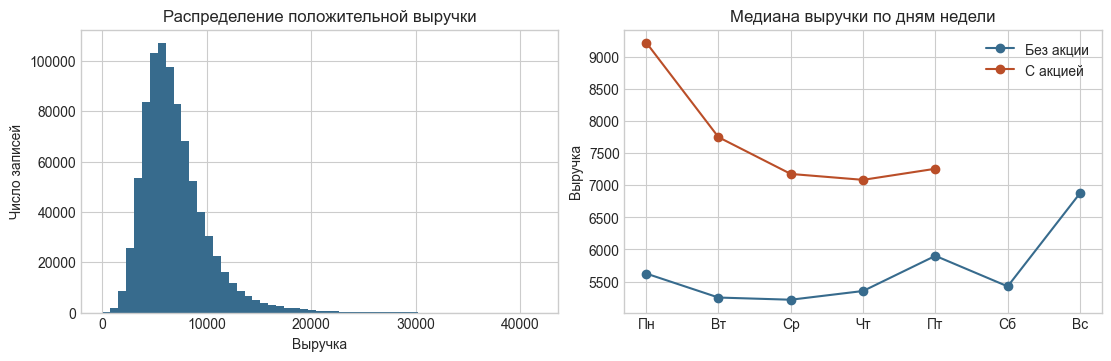

In [2]:
data = report["data"]
display(pd.Series({
    "Дни всех магазинов": data["rows"],
    "Магазины": data["stores"],
    "Начало": data["first_date"],
    "Конец": data["last_date"],
    "Пустые ячейки в имеющихся строках": sum(data["missing"].values()),
    "Строки с нулевой выручкой": data["zero_sales"],
    "Дни, когда магазин не работал": data["closed_days"],
    "Дни работы с нулевой выручкой": data["open_zero_sales"],
}, name="Значение").to_frame())

sales = pd.read_csv(
    root / config["data_path"],
    usecols=["Store", "Date", "Sales", "DayOfWeek", "Promo"],
    parse_dates=["Date"],
)
positive = sales.loc[sales["Sales"] > 0]
by_day = positive.groupby(["DayOfWeek", "Promo"])["Sales"].median().unstack()
by_day.index = ["Пн", "Вт", "Ср", "Чт", "Пт", "Сб", "Вс"]
by_day.columns = ["Без акции", "С акцией"]

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), layout="constrained")
axes[0].hist(positive["Sales"], bins=55, color="#376b8d")
axes[0].set(title="Распределение положительной выручки", xlabel="Выручка", ylabel="Число записей")
by_day.plot(ax=axes[1], marker="o", color=["#376b8d", "#ba4e28"])
axes[1].set(title="Медиана выручки по дням недели", xlabel="", ylabel="Выручка")
plt.show()

Слева показано распределение выручки. Большинство дней с продажами укладывается в диапазон от 2000 до 12 000.

Справа видно, что в дни с акциями выручка обычно выше. Линия для акций заканчивается в пятницу, потому что среди выходных с положительной выручкой акций в данных нет.

## Три исследовательских вопроса

1. Помогает ли информация о тренде?
2. Добавляют ли прошлогодние продажи полезную информацию?
3. Насколько прогноз чувствителен к разовым выбросам в истории?

## Трейн и валидация

| Набор | Даты | Для чего используем |
|---|---|---|
| Трейн | Со 2 марта 2013 по 19 июня 2015 | Обучаем модели. Продажи до 2 марта нужны для расчета первых исторических признаков |
| Последнее окно валидации | С 20 июня по 31 июля 2015 | Входит в сравнение по трем окнам. Здесь подробно разбираем ошибки |

Обучающие данные и окна валидации выделены из `train.csv`.

Последнее окно охватывает последние 42 дня `train.csv`. Для каждого окна строим прогноз сразу на весь период по продажам до его начала. При случайном разбиении в обучение могли бы попасть продажи за даты позже тех, на которых проверяем модель.

Временная валидация включает три 42-дневных окна. Два ранних окна начинаются за 12 и 24 недели до последнего. Для каждого окна заново обучаем модели только на продажах до его начала и считаем признаки по доступной на тот момент истории. По трем окнам считаем среднее и выборочное стандартное отклонение. Сравнения по исследовательским вопросам повторяем на каждом окне по тем же правилам.

Локально прогнозируем на 42 дня для 1115 магазинов. В официальном `test.csv` 48 дней и 856 магазинов. Фактической выручки в файле нет, а в 11 строках магазина 622 пропущен `Open`. Для прогноза на эти даты понадобилось бы уточнить график работы или отдельно определить правило для пропусков.

## Как сравниваем модели

Обе версии линейной регрессии используют номер магазина, день недели, месяц и запланированную акцию. Второй версии дополнительно даем девять признаков из прошлых продаж. Тренд считаем как наклон недельных средних за восемь недель после экспоненциального сглаживания. Еще используем выручку за 28 дней до прогноза, разброс за восемь недель и недавнюю медиану по нужному дню недели.

При обучении логарифмируем выручку. На этой шкале промах на 1000 при выручке 2000 весит больше, чем такой же промах при выручке 20 000. Для расчета RMSPE и MAE переводим прогноз обратно в единицы выручки.

Сравниваем прогнозы на одних и тех же днях с положительной выручкой. В момент прогноза считаем акции и дни работы магазина известными на все шесть недель.

### Как проверяем исследовательские вопросы

1. Тренд. Для каждого окна обучаем полную модель и такую же модель без признака тренда. Сравниваем их на всех днях этого окна с положительной выручкой.
2. Продажи год назад. Сравниваем полную модель с версией без выручки за дату 364 дня назад. Берем только строки, для которых эта запись есть.
3. Выбросы. В истории до валидации отмечаем дни с выручкой не меньше трех медиан для магазина и дня недели. Берем магазины, где такие дни есть и составляют не больше 1% дней с продажами. Удаляем выбросы из копии истории и пересчитываем признаки. Если удаленная строка давала выручку год назад, подставляем среднюю выручку этого магазина за тот же день недели по оставшимся дням с продажами. Сравниваем прогнозы, RMSPE и MAE одной обученной модели на тех же днях валидации. На исходной истории отдельно сравниваем среднее и медиану.

### Как считаем бутстрап-интервалы

Считаем разницу в RMSPE между двумя вариантами на одних и тех же магазинах и датах. Отрицательная разница означает, что второй вариант уменьшил ошибку.

В каждом из 1000 повторов бутстрапа случайно выбираем магазины с возможностью повторов. Берем сразу все дни каждого выбранного магазина и используем одну и ту же выборку для обоих вариантов. По распределению разницы строим доверительные интервалы. Поправку Бонферрони применяем к четырем сравнениям внутри каждого окна.

Даты при бутстрапе фиксированы. Интервалы показывают разброс оценок при изменении состава магазинов внутри окна. Последнее окно уже использовали при разработке, поэтому сравнения считаем предварительными. Ранние окна помогают увидеть, повторяется ли результат на других исторических датах. Вместе эти проверки охватывают три периода одной сети.

### Результаты по трем окнам

In [3]:
def format_number(value, spec):
    return format(value, spec).replace(".", ",")


over_time = report["history_over_time"]
metrics_columns = ["no_history", "with_history", "relative_improvement"]

rows = []
for period in over_time["periods"]:
    start = pd.Timestamp(period["start"]).strftime("%d.%m")
    end = pd.Timestamp(period["end"]).strftime("%d.%m")
    label = f"С {start} по {end}"
    values = [period[name] for name in metrics_columns]
    rows.append([label, *[format_number(value, ".2%") if value is not None else "" for value in values]])

summary = over_time["summary"]
means = [summary[name]["mean"] for name in metrics_columns]
deviations = [summary[name]["std"] for name in metrics_columns]
rows.append(["Среднее", *[format_number(value, ".2%") if value is not None else "" for value in means]])
rows.append([
    "Стандартное отклонение",
    *[f"{format_number(100 * value, '.2f')} п.п." if value is not None else "" for value in deviations],
])

display(pd.DataFrame(rows, columns=[
    "Период в 2015 году", "RMSPE без истории", "RMSPE с историей", "Снижение RMSPE",
]))


,Период в 2015 году,RMSPE без истории,RMSPE с историей,Снижение RMSPE
0,С 03.01 по 13.02,"28,02%","22,33%","20,31%"
1,С 28.03 по 08.05,"23,39%","18,50%","20,88%"
2,С 20.06 по 31.07,"20,33%","15,64%","23,05%"
3,Среднее,"23,91%","18,83%","21,41%"
4,Стандартное отклонение,"3,87 п.п.","3,35 п.п.","1,45 п.п."


### Подробности по последнему окну

,Дни с выручкой,"RMSPE, %",MAE
Без истории,40282.0,20.33,931.78
С историей,40282.0,15.64,746.86


На сколько снизился RMSPE: 23.05%
95%-й бутстрап-интервал для снижения: от 21.05% до 24.93%


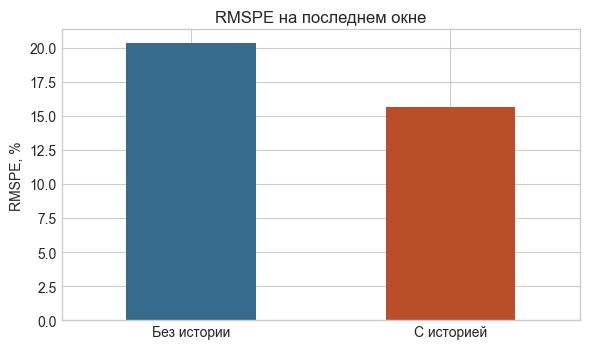

In [4]:
names = {"no_history": "Без истории", "with_history": "С историей"}
main = pd.DataFrame({names[key]: report["experiments"][key] for key in names}).T
main["rmspe"] *= 100
display(main.rename(columns={"rows": "Дни с выручкой", "rmspe": "RMSPE, %", "mae": "MAE"}).round(2))

improvement = report["relative_improvement"] * 100
lower, upper = [bound * 100 for bound in report["bootstrap_95_ci"]]
print(f"На сколько снизился RMSPE: {improvement:.2f}%")
print(f"95%-й бутстрап-интервал для снижения: от {lower:.2f}% до {upper:.2f}%")

ax = main["rmspe"].plot(kind="bar", figsize=(6, 3.6), color=["#376b8d", "#ba4e28"], rot=0)
ax.set(title="RMSPE на последнем окне", xlabel="", ylabel="RMSPE, %")
plt.tight_layout()
plt.show()

Бутстрап-интервал показывает, как результат последнего окна зависит от состава магазинов.

## Где модель ошибается

Сначала выделяем 10% дней с самой низкой положительной выручкой. Остальные дни делим на две группы, с акцией и без акции. Считаем ошибку для каждой группы.

Как часто завышаем прогноз в дни с низкой выручкой: 77.2%
Доля таких дней в сумме квадратов относительных ошибок: 32.9%


,Дни с выручкой,Без истории,С историей
Группа дней,,,
Низкая выручка,4029,42.90,28.39
Дни с акцией,16427,15.42,13.51
Дни без акции,19826,16.39,13.50


,Группа дней,Магазин,Дата,Факт,Прогноз,"Ошибка, %"
0,Низкая выручка,5,2015-06-20,2088,2974,42.4
1,Дни с акцией,551,2015-07-30,6429,7825,21.7
2,Дни без акции,475,2015-07-06,5035,6082,20.8


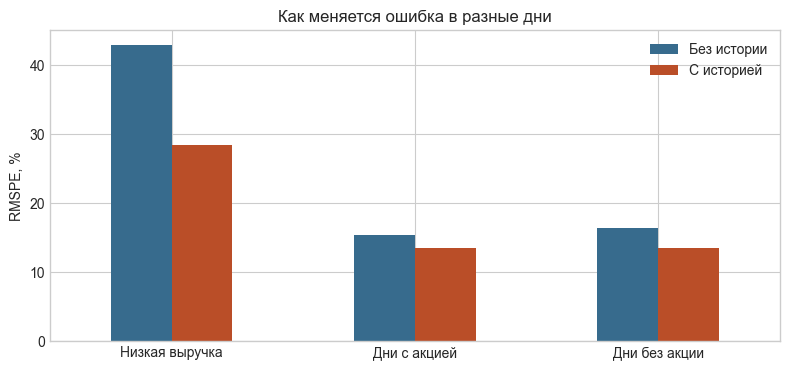

In [5]:
low = scored["Sales"] <= scored["Sales"].quantile(0.10)
groups = {
    "Низкая выручка": scored.loc[low],
    "Дни с акцией": scored.loc[~low & scored["Promo"].eq(1)],
    "Дни без акции": scored.loc[~low & scored["Promo"].eq(0)],
}

example_keys = {
    "Низкая выручка": (5, pd.Timestamp("2015-06-20")),
    "Дни с акцией": (551, pd.Timestamp("2015-07-30")),
    "Дни без акции": (475, pd.Timestamp("2015-07-06")),
}
slices = []
examples = []
for label, rows in groups.items():
    errors = rows[list(names)].sub(rows["Sales"], axis=0).div(rows["Sales"], axis=0)
    rmspe = errors.pow(2).mean().pow(0.5).mul(100)
    slices.append({"Группа дней": label, "Дни с выручкой": len(rows), **rmspe.rename(names).to_dict()})
    example = rows.set_index(["Store", "Date"], drop=False).loc[example_keys[label]]
    examples.append({
        "Группа дней": label,
        "Магазин": example["Store"],
        "Дата": example["Date"].date(),
        "Факт": example["Sales"],
        "Прогноз": round(example["with_history"]),
        "Ошибка, %": round(100 * (example["with_history"] / example["Sales"] - 1), 1),
    })

by_slice = pd.DataFrame(slices).set_index("Группа дней")
signed_error = scored["with_history"] / scored["Sales"] - 1
overprediction = signed_error.loc[low].gt(0).mean()
error_share = signed_error.loc[low].pow(2).sum() / signed_error.pow(2).sum()
print(f"Как часто завышаем прогноз в дни с низкой выручкой: {overprediction:.1%}")
print(f"Доля таких дней в сумме квадратов относительных ошибок: {error_share:.1%}")
display(by_slice.round(2))
display(pd.DataFrame(examples))
ax = by_slice[list(names.values())].plot(
    kind="bar", rot=0, figsize=(8, 3.8), color=["#376b8d", "#ba4e28"]
)
ax.set(title="Как меняется ошибка в разные дни", xlabel="", ylabel="RMSPE, %")
plt.tight_layout()
plt.show()

Для каждой группы зафиксировали пример с ошибкой модели с историей около 90-го процентиля. Ниже разбираем те же магазины и даты.

In [6]:
cutoff = pd.Timestamp(report["validation"]["start"])
prior = sales.loc[sales["Date"].lt(cutoff)]
context = []
for example in examples:
    store_id = example["Магазин"]
    day = pd.Timestamp(example["Дата"])
    row = scored.loc[scored["Store"].eq(store_id) & scored["Date"].eq(day)].iloc[0]
    store_past = prior.loc[prior["Store"].eq(store_id)]
    positive_past = store_past.loc[store_past["Sales"].gt(0)]
    same_weekday = positive_past.loc[positive_past["DayOfWeek"].eq(row["DayOfWeek"])]
    same_promo = same_weekday.loc[same_weekday["Promo"].eq(row["Promo"])]
    recent_weekdays = same_weekday.loc[same_weekday["Date"].ge(cutoff - pd.Timedelta(weeks=8))]
    recent_same_promo = recent_weekdays.loc[recent_weekdays["Promo"].eq(row["Promo"])]
    last_year_date = day - pd.Timedelta(days=config["year_lag_days"])
    last_year = store_past.loc[store_past["Date"].eq(last_year_date), "Sales"]
    last_28 = positive_past.loc[positive_past["Date"].ge(cutoff - pd.Timedelta(days=28))]
    context.append({
        "Магазин": store_id,
        "Дата": day.date(),
        "Типичная выручка в этот день недели при том же промо": same_promo["Sales"].median(),
        "Средняя выручка за 28 дней": last_28["Sales"].mean(),
        "Продажи год назад": last_year.iloc[0] if len(last_year) else None,
        "Медиана недавних таких дней": recent_weekdays["Sales"].median(),
        "Медиана недавних таких дней при том же промо": recent_same_promo["Sales"].median(),
        "Недавних таких дней с акциями": recent_weekdays["Promo"].sum(),
        "Недавних таких дней всего": len(recent_weekdays),
    })
display(pd.DataFrame(context).round(1))

,Магазин,Дата,Типичная выручка в этот день недели при том же промо,Средняя выручка за 28 дней,Продажи год назад,Медиана недавних таких дней,Медиана недавних таких дней при том же промо,Недавних таких дней с акциями,Недавних таких дней всего
0,5,2015-06-20,2000.5,4812.4,1816,2153.5,2153.5,0,8
1,551,2015-07-30,6537.5,6855.3,10644,6658.0,6712.0,5,7
2,475,2015-07-06,5335.0,6994.3,6047,8547.0,5623.0,5,7


- Магазин 5. Выручка была близка к обычной субботе без акции. Модель с историей завысила прогноз. Возможно, она придала слишком большой вес общей недавней выручке магазина.
- Магазин 551. Выручка была близка к типичному четвергу с акцией. Год назад продажи были выше, и это могло завысить прогноз.
- Магазин 475. В большинстве недавних понедельников шли акции. В день ошибки акции не было, поэтому общая медиана могла завысить прогноз.

На графике ниже сравниваем фактическую выручку магазина 1 с прогнозами. Линии опускаются до нуля в дни, когда магазин не работал.

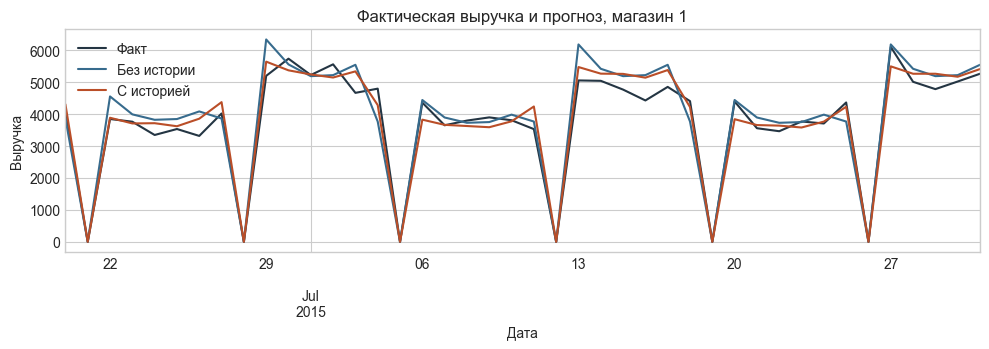

In [7]:
store_id = predictions["Store"].min()
store = predictions.loc[predictions["Store"] == store_id].sort_values("Date").set_index("Date")
lines = store[["Sales", "no_history", "with_history"]].rename(columns={"Sales": "Факт", **names})
ax = lines.plot(figsize=(10, 3.6), color=["#243543", "#376b8d", "#ba4e28"])
ax.set(title=f"Фактическая выручка и прогноз, магазин {store_id}", xlabel="Дата", ylabel="Выручка")
plt.tight_layout()
plt.show()

## Ответы на исследовательские вопросы

В первой таблице подробно показаны результаты последнего окна. Интервалы рассчитаны по 1000 повторам бутстрапа с поправкой на четыре сравнения.

In [8]:
uncertainty = report["comparison_uncertainty"]["comparisons"]
stress = report["spike_sensitivity"]
research = report["research_checks"]

comparisons = [
    ("Добавили тренд", "trend", *research["trend"].values()),
    ("Добавили продажи год назад", "last_year", *research["last_year"].values()),
    ("Убрали выбросы", "remove_spikes", stress["original"], stress["without_spikes"]),
    ("Взяли медиану вместо среднего", "spikes", *research["spikes"].values()),
]

rows = []
for label, key, before, after in comparisons:
    item = uncertainty[key]
    delta = format_number(100 * item["delta_rmspe"], "+.3f")
    low, high = (format_number(100 * value, "+.3f") for value in item["interval"])
    before_rmspe = format_number(before["rmspe"], ".2%")
    after_rmspe = format_number(after["rmspe"], ".2%")
    result = "Включает ноль"
    if item["excludes_zero"]:
        result = "Интервал ниже нуля" if item["delta_rmspe"] < 0 else "Интервал выше нуля"
    rows.append({
        "Проверка": label,
        "RMSPE": f"с {before_rmspe} до {after_rmspe}",
        "Разница и интервал, п.п.": f"{delta} (от {low} до {high})",
        "Итог": result,
    })

display(pd.DataFrame(rows))


,Проверка,RMSPE,"Разница и интервал, п.п.",Итог
0,Добавили тренд,"с 15,49% до 15,64%","+0,149 (от +0,125 до +0,174)",Интервал выше нуля
1,Добавили продажи год назад,"с 16,31% до 15,62%","-0,696 (от -0,769 до -0,621)",Интервал ниже нуля
2,Убрали выбросы,"с 20,40% до 20,32%","-0,073 (от -0,228 до +0,007)",Включает ноль
3,Взяли медиану вместо среднего,"с 20,31% до 20,40%","+0,087 (от -0,352 до +0,440)",Включает ноль


### Сравнения по трем окнам

В таблице указано изменение RMSPE в процентных пунктах, в скобках его интервал. Отрицательное изменение означает снижение ошибки.

In [9]:
period_rows = []
size_rows = []
for label, key, *_ in comparisons:
    row = {"Проверка": label}
    size_row = {"Проверка": label}
    for period in report["history_over_time"]["periods"]:
        start = pd.Timestamp(period["start"]).strftime("%d.%m")
        end = pd.Timestamp(period["end"]).strftime("%d.%m")
        item = period["comparison_uncertainty"]["comparisons"].get(key)
        value = "Мало данных"
        size = "Мало данных"
        if item is not None:
            delta = format_number(100 * item["delta_rmspe"], "+.3f")
            low, high = (format_number(100 * bound, "+.3f") for bound in item["interval"])
            value = f"{delta} (от {low} до {high})"
            size = f"{item['rows']:,} / {item['stores']:,}".replace(",", " ")
        column = f"{start} по {end}"
        row[column] = value
        size_row[column] = size
    period_rows.append(row)
    size_rows.append(size_row)
display(pd.DataFrame(period_rows))
print("Размеры срезов в формате «строки с положительной выручкой / магазины»")
display(pd.DataFrame(size_rows))


,Проверка,03.01 по 13.02,28.03 по 08.05,20.06 по 31.07
0,Добавили тренд,"-0,058 (от -0,160 до +0,044)","+0,008 (от -0,035 до +0,061)","+0,149 (от +0,125 до +0,174)"
1,Добавили продажи год назад,"-0,003 (от -0,094 до +0,064)","-0,202 (от -0,313 до -0,120)","-0,696 (от -0,769 до -0,621)"
2,Убрали выбросы,"+0,006 (от -0,015 до +0,032)","-0,136 (от -0,514 до +0,014)","-0,073 (от -0,228 до +0,007)"
3,Взяли медиану вместо среднего,"+0,340 (от -0,977 до +1,051)","+0,009 (от -0,896 до +0,694)","+0,087 (от -0,352 до +0,440)"


Размеры срезов в формате «строки с положительной выручкой / магазины»


,Проверка,03.01 по 13.02,28.03 по 08.05,20.06 по 31.07
0,Добавили тренд,39 923 / 1 115,37 044 / 1 115,40 282 / 1 115
1,Добавили продажи год назад,39 923 / 1 115,37 044 / 1 115,35 252 / 1 115
2,Убрали выбросы,1 293 / 36,1 287 / 39,1 363 / 38
3,Взяли медиану вместо среднего,1 293 / 36,1 287 / 39,1 363 / 38


В проверке чувствительности для последнего окна удалили из истории 55 выбросов. Если удаленная запись давала выручку год назад, заменяли ее средним по магазину и дню недели.

,Store,Date,Sales,with_history,history_without_spikes
26836,303,2015-07-14,7797,9482.7,7153.3


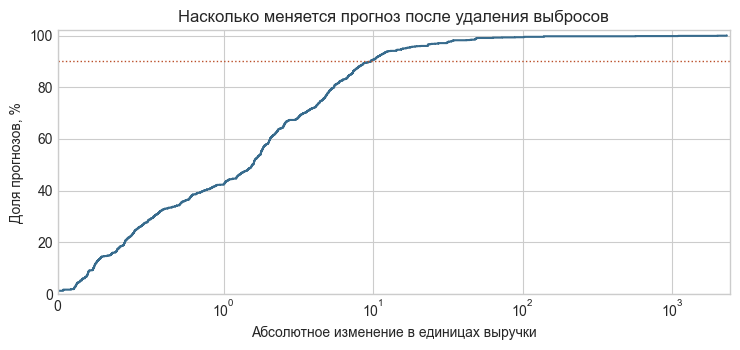

In [10]:
changed = scored.dropna(subset=["history_without_spikes"])
change = (changed["history_without_spikes"] - changed["with_history"]).abs().sort_values()
largest = changed.loc[[change.idxmax()], ["Store", "Date", "Sales", "with_history", "history_without_spikes"]]
display(largest.round(1))

fig, ax = plt.subplots(figsize=(7.5, 3.6))
share = 100 * change.rank(method="max", pct=True)
ax.step(change, share, where="post", color="#376b8d")
ax.axhline(90, color="#ba4e28", linestyle=":", linewidth=1)
ax.set_xscale("symlog", linthresh=1)
ax.set(
    xlim=(0, None),
    ylim=(0, 102),
    title="Насколько меняется прогноз после удаления выбросов",
    xlabel="Абсолютное изменение в единицах выручки",
    ylabel="Доля прогнозов, %",
)
plt.tight_layout()
plt.show()

После удаления выбросов большинство прогнозов изменилось мало. Сильнее всего снизился прогноз магазина 303, где высокая выручка год назад была одним из признаков.

### Интервалы для исследовательских вопросов

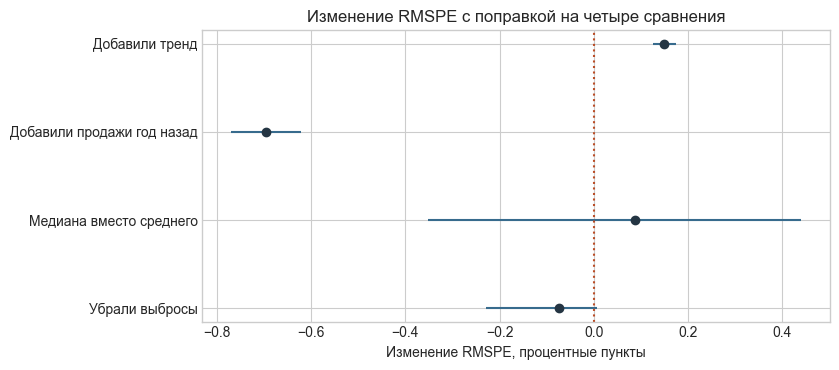

In [11]:
labels = {
    "trend": "Добавили тренд",
    "last_year": "Добавили продажи год назад",
    "spikes": "Медиана вместо среднего",
    "remove_spikes": "Убрали выбросы",
}

comparisons = []
for name, label in labels.items():
    item = uncertainty[name]
    low, high = item["interval"]
    comparisons.append({
        "Сравнение": label,
        "Изменение RMSPE, п.п.": 100 * item["delta_rmspe"],
        "Нижняя граница": 100 * low,
        "Верхняя граница": 100 * high,
    })
intervals = pd.DataFrame(comparisons)

fig, ax = plt.subplots(figsize=(8.5, 3.8))
positions = range(len(intervals))
ax.hlines(positions, intervals["Нижняя граница"], intervals["Верхняя граница"], color="#376b8d")
ax.scatter(intervals["Изменение RMSPE, п.п."], positions, color="#243543", zorder=3)
ax.axvline(0, color="#ba4e28", linestyle=":")
ax.set_yticks(list(positions), labels=intervals["Сравнение"])
ax.invert_yaxis()
ax.set(
    title="Изменение RMSPE с поправкой на четыре сравнения",
    xlabel="Изменение RMSPE, процентные пункты",
)
plt.tight_layout()
plt.show()

## Общий вывод

История продаж снизила RMSPE в среднем на 21,41%. Во всех трех окнах снижение превысило порог гипотезы в 5%. Для последнего окна доверительный интервал тоже целиком выше этого порога. Проверка охватывает три периода одной розничной сети.

Прошлогодняя выручка снизила RMSPE в двух окнах с интервалами ниже нуля. В зимнем окне разница была близка к нулю. Сглаженный тренд ухудшил прогноз в последнем окне, а в ранних окнах интервалы включают ноль. Для удаления выбросов и замены среднего медианой интервалы включают ноль во всех окнах.

Модель чаще завышала прогноз в дни с низкой выручкой. Следующая гипотеза состоит в том, что раздельные недавние медианы для дней с акцией и без нее снизят RMSPE на днях без акции из нижних 10% по положительной выручке. В этом срезе также проверим долю завышений. По всему окну проверим, что RMSPE не вырос. Срез определим после прогноза по фактической выручке.